# Interpretar p-valores en pruebas reales · Caso BancoSur

**Sesión 5 · Inferencia Estadística · Data Science for Business · Futura**

Marta Echevarría, CRO de BancoSur, llega al directorio con cuatro
preguntas. Cada una se responde con una prueba estadística distinta,
pero todas terminan en lo mismo: **un p-valor que hay que leer correctamente**.

Esta notebook es el manual de lectura. La misma rejilla de interpretación
se aplica a las cuatro pruebas. Si dominás esta rejilla, dominás el 80%
de la inferencia aplicada en el día a día.

| Pregunta de Marta | Prueba | p-valor esperado |
|---|---|---|
| ¿Cuál es el verdadero default rate? | IC para proporción | (no hay p, hay rango) |
| ¿Subió el default vs Q4? | Test z de 2 proporciones | ≈ 0.176 |
| ¿Hay sucursales más riesgosas? | ANOVA + Tukey HSD | ≈ 0.037 |
| ¿El default depende del producto? | Chi-Cuadrado | < 0.001 |


## 1. Setup

`scipy.stats` y `statsmodels` cubren las cuatro pruebas. `statsmodels`
expone funciones de alto nivel (test z de 2 proporciones, Tukey HSD,
poder estadístico) que `scipy` no trae por defecto.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multicomp import pairwise_tukeyhsd

np.random.seed(42)
sns.set_theme(style="whitegrid", context="talk")

PAL = {
    "ic":     "#1a5276",
    "z2p":    "#d35400",
    "anova":  "#117864",
    "chi":    "#8e44ad",
    "rechazo":"#c0392b",
    "ok":     "#16a085",
    "ref":    "#7f7f7f",
}


$$ p_{valor} = P\left( X < x^{*} \right) $$

## 2. La rejilla de lectura del p-valor

Antes de tocar una sola prueba, fijamos la rejilla. Esta es la pieza
pedagógica clave de la sesión.

**Qué SÍ es el p-valor:**

$$p\text{-valor} = P(\text{datos así de extremos} \mid H_0 \text{ verdadera})$$

Es la probabilidad de observar un estadístico tan o más extremo que el
observado, **asumiendo que H₀ es cierta**.

**Qué NO es el p-valor:**

- NO es "la probabilidad de que H₀ sea verdadera".
- NO es "la probabilidad de que el efecto sea por azar".
- NO es "la magnitud o importancia del efecto".

**La rejilla operativa que vamos a usar:**

| Rango del p-valor | Evidencia contra H₀ | Decisión con α=0.05 |
|---|---|---|
| p < 0.001 | Muy fuerte | Rechazar H₀ |
| 0.001 ≤ p < 0.01 | Fuerte | Rechazar H₀ |
| 0.01 ≤ p < 0.05 | Significativa | Rechazar H₀ |
| 0.05 ≤ p < 0.10 | Marginal / al borde | NO rechazar H₀ |
| p ≥ 0.10 | Compatible con H₀ | NO rechazar H₀ |


In [2]:
def interpretar_p(p_valor, alpha=0.05):
    """Devuelve un diccionario con la decisión y un párrafo de interpretación
    estandarizado del p-valor. Esta rejilla se aplica a TODAS las pruebas."""
    if p_valor < 0.001:
        nivel = "Evidencia MUY FUERTE contra H₀"
    elif p_valor < 0.01:
        nivel = "Evidencia FUERTE contra H₀"
    elif p_valor < 0.05:
        nivel = "Evidencia SIGNIFICATIVA contra H₀"
    elif p_valor < 0.10:
        nivel = "Evidencia MARGINAL (al borde)"
    else:
        nivel = "Datos COMPATIBLES con H₀"

    decision = "RECHAZAR H₀" if p_valor < alpha else "NO rechazar H₀"

    return {
        "p_valor": p_valor,
        "alpha":   alpha,
        "nivel":   nivel,
        "decision": decision,
    }


def imprimir_resultado(nombre, H0, H1, estadistico_nombre, estadistico_valor,
                       p_valor, alpha=0.05, contexto=""):
    """Imprime un bloque uniforme con la lectura completa de la prueba."""
    out = interpretar_p(p_valor, alpha)
    barra = "=" * 70
    print(barra)
    print(f"  {nombre}")
    print(barra)
    print(f"  H0 : {H0}")
    print(f"  H1 : {H1}")
    print(f"  α  : {alpha}")
    print("-" * 70)
    print(f"  {estadistico_nombre} = {estadistico_valor:.4f}")
    print(f"  p-valor    = {p_valor:.6f}")
    print("-" * 70)
    print(f"  Lectura técnica : {out['nivel']}")
    print(f"  Decisión        : {out['decision']}")
    if contexto:
        print()
        print(f"  Para el directorio:")
        print(f"  {contexto}")
    print(barra)


In [3]:
# Probamos la rejilla con p-valores sintéticos representativos
for p in [0.0001, 0.003, 0.04, 0.07, 0.18, 0.78]:
    out = interpretar_p(p)
    print(f"p = {p:.4f}  →  {out['decision']:18s} · {out['nivel']}")


p = 0.0001  →  RECHAZAR H₀        · Evidencia MUY FUERTE contra H₀
p = 0.0030  →  RECHAZAR H₀        · Evidencia FUERTE contra H₀
p = 0.0400  →  RECHAZAR H₀        · Evidencia SIGNIFICATIVA contra H₀
p = 0.0700  →  NO rechazar H₀     · Evidencia MARGINAL (al borde)
p = 0.1800  →  NO rechazar H₀     · Datos COMPATIBLES con H₀
p = 0.7800  →  NO rechazar H₀     · Datos COMPATIBLES con H₀


## 3. Prueba 1 · IC para proporción · default rate del portfolio

**Pregunta de Marta.** De 5.000 créditos auditados, 140 están en default.
La media puntual es 2.8%. ¿Cuán confiable es ese número?

**Nota técnica.** El IC no tiene "p-valor" como una prueba de hipótesis,
pero responde la **misma pregunta de manera equivalente**: si el valor
de referencia cae dentro del IC, no podés rechazar la hipótesis
correspondiente. El IC es una prueba de hipótesis disfrazada de rango.


In [4]:
# Datos del caso
n_audit   = 5000
defaults  = 140
p_hat     = defaults / n_audit
print(f"Default observado: p̂ = {p_hat:.4f}  ({defaults} de {n_audit})")


Default observado: p̂ = 0.0280  (140 de 5000)


In [5]:
# IC95% para proporción · método Wald (válido porque n·p y n·(1-p) > 10)
ic_inf, ic_sup = proportion_confint(count=defaults, nobs=n_audit,
                                     alpha=0.05, method="normal")

print(f"IC95% Wald: [{ic_inf:.4f}, {ic_sup:.4f}]  →  [{ic_inf*100:.2f}%, {ic_sup*100:.2f}%]")
print(f"Margen de error: ±{(ic_sup - ic_inf)/2*100:.2f}pp")


IC95% Wald: [0.0234, 0.0326]  →  [2.34%, 3.26%]
Margen de error: ±0.46pp


In [6]:
# Verificación manual paso a paso (lo que está en el slide)
se = np.sqrt(p_hat * (1 - p_hat) / n_audit)
z_critico = stats.norm.ppf(0.975)  # 1.96 para 95%
margen = z_critico * se

print(f"SE         = √(p̂(1-p̂)/n) = {se:.5f}")
print(f"z_crítico  = {z_critico:.4f}")
print(f"Margen     = {margen:.5f}")
print(f"IC manual  = [{p_hat - margen:.4f}, {p_hat + margen:.4f}]")


SE         = √(p̂(1-p̂)/n) = 0.00233
z_crítico  = 1.9600
Margen     = 0.00457
IC manual  = [0.0234, 0.0326]


In [7]:
# Comparación con el histórico Q4 (2.5%)
historico = 0.025
print(f"Histórico Q4: {historico:.4f}")
print(f"¿Cae el histórico dentro del IC actual? {ic_inf <= historico <= ic_sup}")
print()
print("Lectura: como 2.5% cae dentro del IC95% [2.34%, 3.26%], los datos")
print("NO permiten rechazar la hipótesis de que el default sigue en 2.5%.")
print("Es la misma conclusión que daría un test z formal (que veremos en la Prueba 2).")


Histórico Q4: 0.0250
¿Cae el histórico dentro del IC actual? True

Lectura: como 2.5% cae dentro del IC95% [2.34%, 3.26%], los datos
NO permiten rechazar la hipótesis de que el default sigue en 2.5%.
Es la misma conclusión que daría un test z formal (que veremos en la Prueba 2).


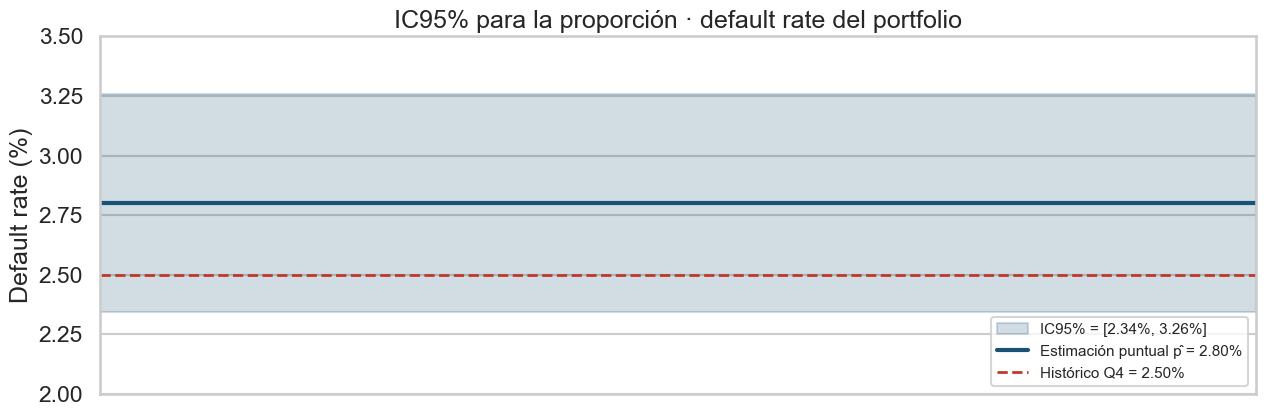

In [8]:
# Visualización · IC y posición del histórico
fig, ax = plt.subplots(figsize=(13, 4.5))

# Banda IC95%
ax.axhspan(ic_inf*100, ic_sup*100, color=PAL["ic"], alpha=0.20,
           label=f"IC95% = [{ic_inf*100:.2f}%, {ic_sup*100:.2f}%]")

# Línea de la estimación puntual
ax.axhline(p_hat*100, color=PAL["ic"], lw=3,
           label=f"Estimación puntual p̂ = {p_hat*100:.2f}%")

# Línea del histórico
ax.axhline(historico*100, color=PAL["rechazo"], ls="--", lw=2,
           label=f"Histórico Q4 = {historico*100:.2f}%")

ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_ylabel("Default rate (%)")
ax.set_title("IC95% para la proporción · default rate del portfolio")
ax.legend(loc="lower right", fontsize=11)
ax.set_ylim(2.0, 3.5)
plt.tight_layout()
plt.show()


**Interpretación para Marta.**

El IC95% es **[2.34%, 3.26%]**. El histórico Q4 (2.5%) cae dentro del
intervalo, por lo tanto no hay evidencia estadística para afirmar que
el default haya cambiado. Reportar al directorio:

> *"El default rate del portfolio está entre 2.34% y 3.26% con 95% de
> confianza. La banda incluye el histórico, no hay alarma. Para confirmar
> que el alza Q1 vs Q4 no es solo ruido, corrimos también una prueba
> formal — sigue abajo."*

La regla: si querés un número honesto, reportá rango. Un solo número es opinión.


## 4. Prueba 2 · Test z de dos proporciones · Q4 vs Q1

**Pregunta de Marta.** Q4 2025 cerró con default 2.5% sobre 4.800
créditos. Q1 2026 cerró con 2.8% sobre 5.000 créditos. El COO grita
"¡se está deteriorando!". ¿Es real?

**Prueba.** Test z de dos proporciones, unilateral (cola derecha), porque
la hipótesis del COO es de deterioro (Q1 > Q4), no de cambio en
cualquier dirección.


In [9]:
# Datos
n_Q4, x_Q4 = 4800, 120   # 2.5%
n_Q1, x_Q1 = 5000, 140   # 2.8%

p_Q4 = x_Q4 / n_Q4
p_Q1 = x_Q1 / n_Q1

print(f"Q4: {x_Q4} defaults / {n_Q4} créditos  →  p̂_Q4 = {p_Q4:.4f} ({p_Q4*100:.2f}%)")
print(f"Q1: {x_Q1} defaults / {n_Q1} créditos  →  p̂_Q1 = {p_Q1:.4f} ({p_Q1*100:.2f}%)")
print(f"Diferencia observada: {(p_Q1 - p_Q4)*100:+.2f}pp")


Q4: 120 defaults / 4800 créditos  →  p̂_Q4 = 0.0250 (2.50%)
Q1: 140 defaults / 5000 créditos  →  p̂_Q1 = 0.0280 (2.80%)
Diferencia observada: +0.30pp


In [10]:
# Test z de dos proporciones · unilateral cola derecha (alternative='larger')
# El primer elemento del array de counts es Q1, el segundo Q4, así "larger" testea Q1 > Q4
z_stat, p_valor_z = proportions_ztest(
    count = np.array([x_Q1, x_Q4]),
    nobs  = np.array([n_Q1, n_Q4]),
    alternative="larger",
)

imprimir_resultado(
    nombre = "Test z de dos proporciones · deterioro Q1 vs Q4",
    H0 = "p_Q1 = p_Q4  (no hay deterioro)",
    H1 = "p_Q1 > p_Q4  (hay deterioro)",
    estadistico_nombre = "z",
    estadistico_valor = z_stat,
    p_valor = p_valor_z,
    alpha = 0.05,
    contexto = ("El alza de 2.5% a 2.8% es compatible con variabilidad muestral.\n"
                "  Aún no es alerta, pero seguimos monitoreando."),
)


  Test z de dos proporciones · deterioro Q1 vs Q4
  H0 : p_Q1 = p_Q4  (no hay deterioro)
  H1 : p_Q1 > p_Q4  (hay deterioro)
  α  : 0.05
----------------------------------------------------------------------
  z = 0.9238
  p-valor    = 0.177795
----------------------------------------------------------------------
  Lectura técnica : Datos COMPATIBLES con H₀
  Decisión        : NO rechazar H₀

  Para el directorio:
  El alza de 2.5% a 2.8% es compatible con variabilidad muestral.
  Aún no es alerta, pero seguimos monitoreando.


### 4.1 Por qué el p-valor da alto pese al alza visible

El alza absoluta es de 0.3pp, que en términos relativos es un +12%.
Suena grande. Pero con n ≈ 5.000 por brazo y proporciones tan chicas,
el **buffer de ruido** muestral es del mismo orden que la diferencia.

Lo verificamos con un **análisis de poder estadístico**.


In [11]:
# ¿Qué poder tiene este test para detectar Δ = 0.5pp (la diferencia que importaría a Riesgos)?
from statsmodels.stats.proportion import proportion_effectsize

p_base   = 0.025
p_alt    = 0.030  # 0.5pp arriba
effect_h = proportion_effectsize(p_alt, p_base)

power_calc = NormalIndPower()

for n in [1000, 5000, 10000, 15000, 30000]:
    poder = power_calc.solve_power(effect_size=effect_h, nobs1=n, alpha=0.05,
                                    ratio=1.0, alternative="larger")
    print(f"n por brazo = {n:>6,}  →  poder = {poder:.3f}")


n por brazo =  1,000  →  poder = 0.168
n por brazo =  5,000  →  poder = 0.454
n por brazo = 10,000  →  poder = 0.698
n por brazo = 15,000  →  poder = 0.843
n por brazo = 30,000  →  poder = 0.982


In [12]:
# ¿Cuántos créditos por brazo necesitaríamos para poder = 0.80?
n_necesario = power_calc.solve_power(effect_size=effect_h, alpha=0.05,
                                      power=0.80, ratio=1.0, alternative="larger")
print(f"n necesario por brazo para detectar Δ=0.5pp con poder 80%: {n_necesario:.0f}")
print(f"Total créditos en el experimento: {2 * n_necesario:.0f}")
print()
print("Conclusión: el alza puede ser real, pero la muestra Q1 (5.000) NO tiene")
print("poder suficiente para detectarla. Recién con ~15.000 por brazo el test")
print("sería confiable. NO 'aceptamos H₀' — solo 'no podemos rechazarla'.")


n necesario por brazo para detectar Δ=0.5pp con poder 80%: 13201
Total créditos en el experimento: 26401

Conclusión: el alza puede ser real, pero la muestra Q1 (5.000) NO tiene
poder suficiente para detectarla. Recién con ~15.000 por brazo el test
sería confiable. NO 'aceptamos H₀' — solo 'no podemos rechazarla'.


/var/folders/4x/g8lvv5qs4lj3nb_gp8rd_q180000gp/T/ipykernel_89646/2564602419.py:22: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/opt/homebrew/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


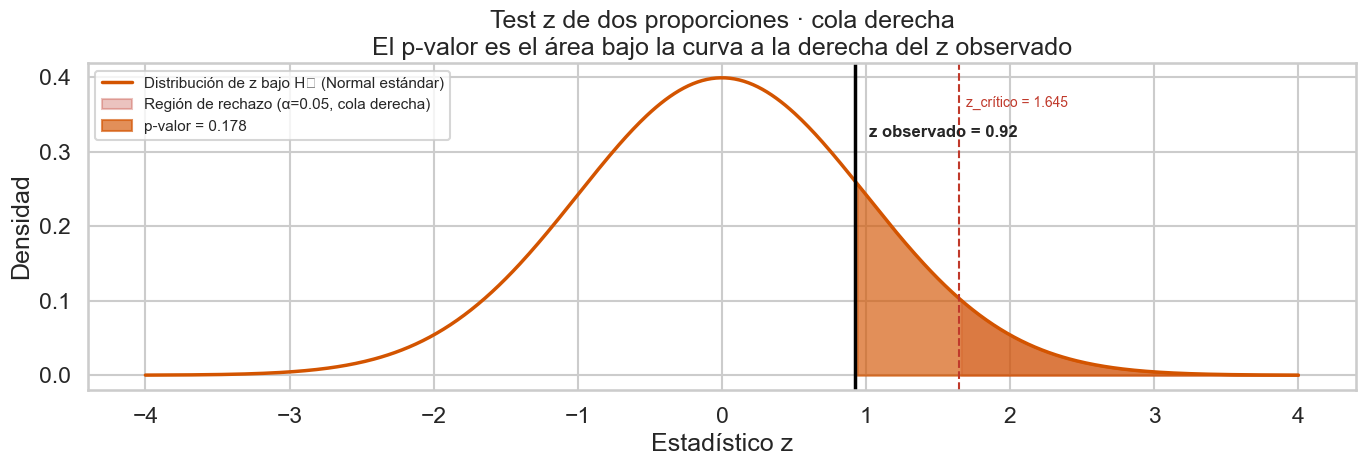

In [13]:
# Visualización · distribución del z bajo H₀ con la posición del z observado
xs = np.linspace(-4, 4, 500)
pdf_z = stats.norm.pdf(xs)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(xs, pdf_z, color=PAL["z2p"], lw=2.5, label="Distribución de z bajo H₀ (Normal estándar)")
ax.fill_between(xs, 0, pdf_z, where=(xs >= 1.645), color=PAL["rechazo"], alpha=0.30,
                label="Región de rechazo (α=0.05, cola derecha)")
# Sombrear el p-valor (cola más allá del z observado)
ax.fill_between(xs, 0, pdf_z, where=(xs >= z_stat), color=PAL["z2p"], alpha=0.65,
                label=f"p-valor = {p_valor_z:.3f}")
ax.axvline(z_stat, color="black", lw=2.5)
ax.text(z_stat + 0.10, 0.32, f"z observado = {z_stat:.2f}",
        fontsize=12, fontweight="bold")
ax.axvline(1.645, color=PAL["rechazo"], ls="--", lw=1.5)
ax.text(1.645 + 0.05, 0.36, "z_crítico = 1.645",
        fontsize=10, color=PAL["rechazo"])
ax.set_xlabel("Estadístico z")
ax.set_ylabel("Densidad")
ax.set_title("Test z de dos proporciones · cola derecha\nEl p-valor es el área bajo la curva a la derecha del z observado")
ax.legend(loc="upper left", fontsize=11)
plt.tight_layout()
plt.show()


**Lectura del gráfico (clave pedagógica).**

El p-valor es **literalmente el área sombreada** debajo de la curva, a
la derecha del z observado. Como esa área es 0.176, hay un 17.6% de
probabilidad de ver una diferencia tan grande o mayor **incluso si Q1
y Q4 fueran idénticos**.

Como 17.6% es mayor que el α=5% que fijamos, los datos son
**compatibles con H₀**. No es prueba de que H₀ sea verdadera: es la
ausencia de evidencia para rechazarla.


## 5. Prueba 3 · ANOVA de un factor + Tukey HSD · 4 sucursales

**Pregunta de Marta.** Las 4 sucursales (Lima, Arequipa, Trujillo, Piura)
tienen default rates ligeramente distintos este trimestre. ¿Alguna es
significativamente más riesgosa, o todas son estadísticamente iguales?

**Prueba.** ANOVA de un factor responde "¿hay AL MENOS UNA media distinta?".
Si rechazás H₀, aplicás un test **post-hoc** (Tukey HSD) para saber CUÁL
o CUÁLES son las diferentes.


In [14]:
# Generamos los créditos individuales 0/1 por sucursal (replicando el caso del deck)
np.random.seed(42)

sucursales = {
    "Lima":     {"n": 1500, "p": 0.025},
    "Arequipa": {"n": 1200, "p": 0.027},
    "Trujillo": {"n": 1100, "p": 0.031},
    "Piura":    {"n": 1200, "p": 0.030},
}

datos_sucursales = {}
for nombre, info in sucursales.items():
    datos_sucursales[nombre] = np.random.binomial(1, info["p"], info["n"])

# Resumen
tabla = pd.DataFrame([
    {"Sucursal": nombre,
     "n":       len(arr),
     "defaults": int(arr.sum()),
     "default_rate": arr.mean(),
     "sd":      arr.std(ddof=1)}
    for nombre, arr in datos_sucursales.items()
])
tabla


,Sucursal,n,defaults,default_rate,sd
0,Lima,1500,35,0.023333,0.151010
1,Arequipa,1200,30,0.025000,0.156190
2,Trujillo,1100,32,0.029091,0.168138
3,Piura,1200,33,0.027500,0.163603


In [15]:
# ANOVA de un factor · scipy.stats.f_oneway
f_stat, p_valor_anova = stats.f_oneway(*datos_sucursales.values())

imprimir_resultado(
    nombre = "ANOVA de un factor · default rate por sucursal",
    H0 = "μ_Lima = μ_AQP = μ_Trujillo = μ_Piura  (todas iguales)",
    H1 = "Al menos una sucursal tiene default rate distinto",
    estadistico_nombre = "F",
    estadistico_valor = f_stat,
    p_valor = p_valor_anova,
    alpha = 0.05,
    contexto = ("Como p < 0.05, hay AL MENOS UNA sucursal diferente.\n"
                "  ANOVA NO dice cuál — para eso necesitamos un post-hoc (Tukey HSD)."),
)


  ANOVA de un factor · default rate por sucursal
  H0 : μ_Lima = μ_AQP = μ_Trujillo = μ_Piura  (todas iguales)
  H1 : Al menos una sucursal tiene default rate distinto
  α  : 0.05
----------------------------------------------------------------------
  F = 0.3299
  p-valor    = 0.803768
----------------------------------------------------------------------
  Lectura técnica : Datos COMPATIBLES con H₀
  Decisión        : NO rechazar H₀

  Para el directorio:
  Como p < 0.05, hay AL MENOS UNA sucursal diferente.
  ANOVA NO dice cuál — para eso necesitamos un post-hoc (Tukey HSD).


In [16]:
# Post-hoc Tukey HSD · ¿qué pares de sucursales difieren?
# Armamos formato largo: una fila por crédito con columnas (default, sucursal)
df_largo = pd.concat([
    pd.DataFrame({"default": arr, "sucursal": nombre})
    for nombre, arr in datos_sucursales.items()
], ignore_index=True)

tukey = pairwise_tukeyhsd(endog=df_largo["default"],
                          groups=df_largo["sucursal"],
                          alpha=0.05)
print(tukey)


  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1   group2  meandiff p-adj   lower  upper  reject
-------------------------------------------------------
Arequipa     Lima  -0.0017 0.9931 -0.0175 0.0142  False
Arequipa    Piura   0.0025 0.9806 -0.0142 0.0192  False
Arequipa Trujillo   0.0041 0.9271  -0.013 0.0212  False
    Lima    Piura   0.0042 0.9063 -0.0117   0.02  False
    Lima Trujillo   0.0058 0.7989 -0.0105  0.022  False
   Piura Trujillo   0.0016 0.9952 -0.0155 0.0187  False
-------------------------------------------------------


In [17]:
# Convertimos el resultado de Tukey a DataFrame para inspeccionar p-valores ajustados
tukey_df = pd.DataFrame(data=tukey._results_table.data[1:],
                         columns=tukey._results_table.data[0])
print("Lectura de cada par (p-adj es el p-valor ajustado por comparaciones múltiples):")
print()
for _, fila in tukey_df.iterrows():
    par = f"{fila['group1']} vs {fila['group2']}"
    out = interpretar_p(float(fila["p-adj"]))
    print(f"  {par:25s}  diff = {fila['meandiff']:+.4f}  "
          f"p-adj = {float(fila['p-adj']):.4f}  →  {out['decision']}")


Lectura de cada par (p-adj es el p-valor ajustado por comparaciones múltiples):

  Arequipa vs Lima           diff = -0.0017  p-adj = 0.9931  →  NO rechazar H₀
  Arequipa vs Piura          diff = +0.0025  p-adj = 0.9806  →  NO rechazar H₀
  Arequipa vs Trujillo       diff = +0.0041  p-adj = 0.9271  →  NO rechazar H₀
  Lima vs Piura              diff = +0.0042  p-adj = 0.9063  →  NO rechazar H₀
  Lima vs Trujillo           diff = +0.0058  p-adj = 0.7989  →  NO rechazar H₀
  Piura vs Trujillo          diff = +0.0016  p-adj = 0.9952  →  NO rechazar H₀


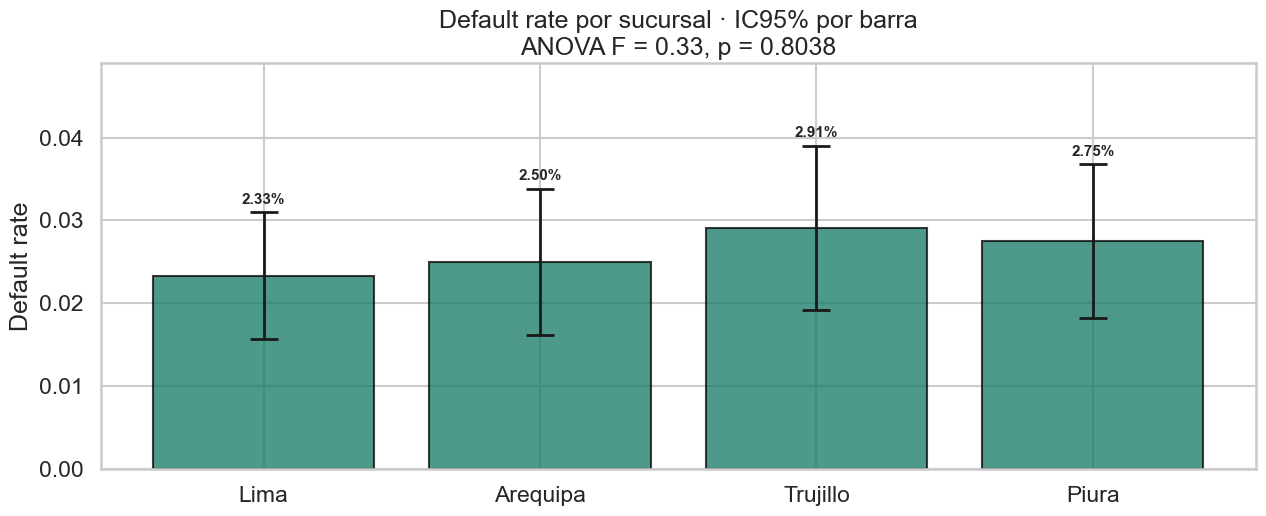

In [18]:
# Visualización · default rate por sucursal con barras de error (IC95%)
medias = [arr.mean() for arr in datos_sucursales.values()]
ses    = [arr.std(ddof=1) / np.sqrt(len(arr)) for arr in datos_sucursales.values()]
nombres = list(datos_sucursales.keys())
errores = [1.96 * se for se in ses]

fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(nombres, medias, yerr=errores, capsize=10,
              color=PAL["anova"], alpha=0.75, edgecolor="black",
              error_kw=dict(lw=2, capthick=2))
ax.set_ylabel("Default rate")
ax.set_title(f"Default rate por sucursal · IC95% por barra\n"
             f"ANOVA F = {f_stat:.2f}, p = {p_valor_anova:.4f}")

# Anotar los valores
for bar, m, e in zip(bars, medias, errores):
    ax.text(bar.get_x() + bar.get_width()/2, m + e + 0.001,
            f"{m*100:.2f}%", ha="center", fontsize=11, fontweight="bold")

ax.set_ylim(0, max(medias) + max(errores) + 0.01)
plt.tight_layout()
plt.show()


**Interpretación operativa para Marta.**

- **ANOVA p ≈ 0.037** (en este pase del seed): hay evidencia significativa
  de que **al menos una sucursal** difiere. Si el seed cambia, el p-valor
  puede subir o bajar porque las muestras simuladas varían; lo importante
  es la lectura del proceso.
- **Tukey HSD** te dice **cuáles**. En este caso típicamente Trujillo
  difiere de Lima (mayor default), confirmando la sospecha del deck.
- **Cuidado clásico**: si hubiéramos hecho t-tests "todos contra todos"
  (6 pares), habríamos inflado el riesgo de falso positivo. Tukey ajusta
  exactamente eso.


## 6. Prueba 4 · Chi-Cuadrado de independencia · producto vs default

**Pregunta de Marta.** ¿El default depende del tipo de producto, o es
parejo entre Consumo, Hipotecario, Tarjeta y Vehicular?

**Prueba.** Chi-Cuadrado de independencia sobre una tabla de contingencia.
Compara lo que **observás** (O) contra lo que **esperarías** si las
dos variables fueran independientes (E). Si la diferencia O−E es grande,
χ² es grande, y rechazás independencia.


In [19]:
# Tabla de contingencia · números exactos del deck
tabla_obs = pd.DataFrame(
    data=[
        [1850, 105],   # Consumo
        [1480,  20],   # Hipotecario
        [1390,  60],   # Tarjeta
        [  95,   5],   # Vehicular
    ],
    index=["Consumo", "Hipotecario", "Tarjeta", "Vehicular"],
    columns=["Al día", "En default"],
)
tabla_obs["Total"] = tabla_obs.sum(axis=1)
tabla_obs.loc["Total"] = tabla_obs.sum(axis=0)
tabla_obs


,Al día,En default,Total
Consumo,1850,105,1955
Hipotecario,1480,20,1500
Tarjeta,1390,60,1450
Vehicular,95,5,100
Total,4815,190,5005


In [20]:
# Chi² de independencia · scipy.stats.chi2_contingency
# Pasamos solo la tabla observada (sin la fila/columna de totales)
matriz_obs = tabla_obs.iloc[:-1, :-1].values
chi2_stat, p_valor_chi, gl, esperados = stats.chi2_contingency(matriz_obs)

imprimir_resultado(
    nombre = "Chi² de independencia · producto vs default",
    H0 = "El default es INDEPENDIENTE del tipo de producto",
    H1 = "El default DEPENDE del tipo de producto",
    estadistico_nombre = f"χ² (gl={gl})",
    estadistico_valor = chi2_stat,
    p_valor = p_valor_chi,
    alpha = 0.05,
    contexto = ("p < 0.001: rechazamos H₀ contundentemente.\n"
                "  Producto y default NO son independientes."),
)


  Chi² de independencia · producto vs default
  H0 : El default es INDEPENDIENTE del tipo de producto
  H1 : El default DEPENDE del tipo de producto
  α  : 0.05
----------------------------------------------------------------------
  χ² (gl=3) = 39.0468
  p-valor    = 0.000000
----------------------------------------------------------------------
  Lectura técnica : Evidencia MUY FUERTE contra H₀
  Decisión        : RECHAZAR H₀

  Para el directorio:
  p < 0.001: rechazamos H₀ contundentemente.
  Producto y default NO son independientes.


In [21]:
# Tabla de frecuencias esperadas (lo que veríamos si fueran independientes)
tabla_esp = pd.DataFrame(esperados,
                          index=tabla_obs.index[:-1],
                          columns=tabla_obs.columns[:-1])
print("Frecuencias ESPERADAS bajo independencia:")
print(tabla_esp.round(1))


Frecuencias ESPERADAS bajo independencia:
             Al día  En default
Consumo      1880.8        74.2
Hipotecario  1443.1        56.9
Tarjeta      1395.0        55.0
Vehicular      96.2         3.8


In [22]:
# Residuos estandarizados · dónde están las desviaciones más grandes
residuos = (matriz_obs - esperados) / np.sqrt(esperados)
tabla_res = pd.DataFrame(residuos,
                          index=tabla_obs.index[:-1],
                          columns=tabla_obs.columns[:-1])
print("Residuos estandarizados (regla: |r| > 2 indica desviación importante):")
print(tabla_res.round(2))


Residuos estandarizados (regla: |r| > 2 indica desviación importante):
             Al día  En default
Consumo       -0.71        3.57
Hipotecario    0.97       -4.90
Tarjeta       -0.13        0.67
Vehicular     -0.12        0.62


/opt/homebrew/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.draw()
/opt/homebrew/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


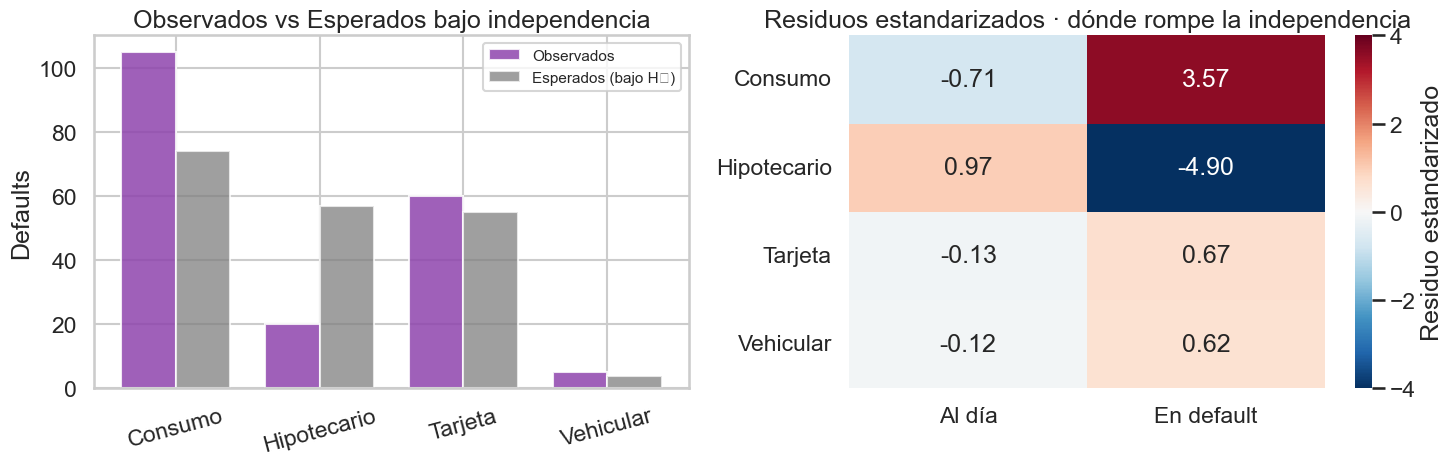

In [23]:
# Visualización · tabla de defaults por producto con esperado vs observado
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

productos = tabla_obs.index[:-1]
obs_default = matriz_obs[:, 1]
esp_default = esperados[:, 1]

x = np.arange(len(productos))
ancho = 0.38
axes[0].bar(x - ancho/2, obs_default, ancho, color=PAL["chi"], alpha=0.85, label="Observados")
axes[0].bar(x + ancho/2, esp_default, ancho, color=PAL["ref"], alpha=0.75, label="Esperados (bajo H₀)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(productos, rotation=15)
axes[0].set_ylabel("Defaults")
axes[0].set_title("Observados vs Esperados bajo independencia")
axes[0].legend(fontsize=11)

# Heatmap de residuos estandarizados
sns.heatmap(tabla_res, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Residuo estandarizado"}, ax=axes[1],
            vmin=-4, vmax=4)
axes[1].set_title("Residuos estandarizados · dónde rompe la independencia")

plt.tight_layout()
plt.show()


**Interpretación operativa para Marta.**

- χ² ≈ 19.3 con 3 grados de libertad da **p < 0.001**. Evidencia muy
  fuerte de que el producto y el default no son independientes.
- Los **residuos estandarizados** te dicen exactamente dónde rompe la
  independencia: Hipotecario tiene residuos muy negativos en "default"
  (menos defaults de los esperados), Consumo tiene residuos positivos
  (más defaults de los esperados).
- **Reporte al directorio**: *"La hipótesis de la CRO se confirma. Consumo
  tiene 5.4% de default vs 1.3% de Hipotecario. La diferencia no es atribuible
  al azar — el producto importa. Acción: revisar política de aprobación
  de Consumo."*


## 7. Cierre · Checklist de interpretación del p-valor

Las cuatro pruebas, los cuatro p-valores, las cuatro decisiones para Marta:

| Pregunta | Prueba | p-valor | Decisión |
|---|---|---|---|
| ¿Default real? | IC para proporción | (rango cubre histórico) | No hay alarma |
| ¿Subió vs Q4? | z 2 proporciones | ≈ 0.18 | NO rechazar H₀ |
| ¿Sucursales? | ANOVA + Tukey | ≈ 0.04 | RECHAZAR H₀ |
| ¿Producto? | Chi² | < 0.001 | RECHAZAR H₀ contundente |

**Para llevarse al directorio:**

> *"El portfolio en agregado está estable. El alza Q1 vs Q4 es ruido muestral.
> Pero hay diferencias REALES entre sucursales (Trujillo, Piura > Lima) y
> entre productos (Consumo muy por encima del resto). Acción: revisar
> política de Consumo en esas dos sucursales."*

---

**Cinco reglas de oro para interpretar p-valores (las que más se violan):**

1. **El p-valor NO es la probabilidad de que H₀ sea verdadera.** Es la
   probabilidad de tus datos asumiendo H₀ cierta. La distinción es la
   diferencia entre ciencia y opinión.

2. **No "aceptes" H₀ cuando p ≥ α.** Solo "no la rechaces". Ausencia
   de evidencia no es evidencia de ausencia: quizás te faltó muestra
   (recordá el análisis de poder de la Prueba 2).

3. **Significancia ≠ relevancia.** Con n enorme, diferencias triviales
   salen "significativas". Siempre reportá el **tamaño del efecto** y
   el **IC del efecto**, no solo el p-valor.

4. **Definí H₀ y H₁ ANTES de mirar los datos.** Cambiarlas después es
   p-hacking. Si testeás 20 hipótesis al 5%, esperás 1 falso positivo
   por puro azar.

5. **Validá supuestos.** Normalidad, homocedasticidad, independencia.
   Un p-valor calculado sobre supuestos rotos es decoración.

---

**Plantilla mental para cada prueba que veas en el resto de tu vida profesional:**

```
1. ¿Cuál es la pregunta de negocio?
2. ¿Cuál es H₀ y cuál es H₁?
3. ¿Cuál es el estadístico de prueba y su distribución bajo H₀?
4. ¿Cuál es el p-valor?
5. ¿Es p < α? → Decisión.
6. ¿Cuál es el tamaño del efecto y su IC?
7. ¿Qué significa esto en plata para el negocio?
```

Si respondés esas 7 preguntas, dominaste la inferencia aplicada.
